# 千葉の自転車盗：実行例

これは解説用の実行例です。提出用は新しい空のNotebookを作成してください。

千葉県警察が2025年分として公開している自転車盗CSV・10,054件（2026年11月18日取得）。発生年月日（始期）は2019〜2025年と不明を含みます。

出典：https://www.police.pref.chiba.jp/seisoka/safe-life_publicspace-statistics_00002.html

[公式ページを開く](https://www.police.pref.chiba.jp/seisoka/safe-life_publicspace-statistics_00002.html) → 令和7年の「自転車盗（CSV形式）」をダウンロード。

## 1. 準備
ダウンロードしたファイルを `bike.csv` に名前変更し、Notebookと同じフォルダに保存。文字コードはCP932です。標準ライブラリのルートは追加インストール不要。

## 2. CSVを読む

csv.DictReaderは、各行を「列名: 値」の辞書にします。listで全行をまとめ、lenで件数を確認します。

In [1]:
# 読み込むファイルを設定する（Notebookと同じフォルダに保存）
filename = "bike.csv"
encoding = "cp932"

# 千葉県警のCSVはShift-JIS（CP932）。追加インストールは不要
import csv
with open(filename, encoding=encoding, newline="") as file:
    incidents = list(csv.DictReader(file))

# 1行が1件の事件。件数を確認する
len(incidents)

10054

## 3. 1件の内容を見る

incidentsはリスト、incidents[0]は最初の事件の辞書。列名をキーに値を取り出します。列名一覧は list(incidents[0]) で確認。

In [2]:
# 最初の事件から、必要な列を選んで確認する
row = incidents[0]
row["市区町村（発生地）"], row["発生時（始期）"], row["施錠関係"]

('千葉市中央区', '15', '施錠した')

## 4. forで数える

counts.get(label, 0)は、登録済みなら件数、未登録なら0。その値に1を足して保存します。事件の総数と集計の合計が一致するか確かめよう。

In [3]:
# 集計したい列を選ぶ
column = "施錠関係"
counts = {}

# 同じ値が出てくるたびに、件数を1増やす
for row in incidents:
    label = row[column]
    counts[label] = counts.get(label, 0) + 1

counts

{'施錠した': 3175, '施錠せず': 6879}

## 5. 市区町村を絞る

==は一致の比較。appendはリストの末尾へ1件追加。市名を変えて再実行し、件数を比較してみよう。

In [4]:
# 調べたい市区町村を指定する
city = "柏市"
selected = []

# 条件に合う事件だけ、新しいリストへ入れる
for row in incidents:
    if row["市区町村（発生地）"] == city:
        selected.append(row)

len(selected)

564

## 6. ランキング

CounterはPython標準ライブラリ。未登録のキーは0から数えられます。most_common(5)は件数の多い上位5組を返します。件数は人口や駐輪台数で補正した被害率ではありません。

In [5]:
column = "市区町村（発生地）"
top_n = 5

# Counterは標準ライブラリ。未登録の値は0件から数える
from collections import Counter
counts = Counter()
for row in incidents:
    counts[row[column]] += 1

# 件数の多い上位5組を取り出す
top_places = counts.most_common(top_n)
top_places

[('船橋市', 1299), ('市川市', 871), ('松戸市', 725), ('千葉市中央区', 708), ('柏市', 564)]

## 6+. 結果を読みやすく

forで各組を取り出し、f文字列で表示を整えます。{count:>6,}は6文字幅で右寄せし、3桁ごとにカンマを付けます。日本語の市名より先に数字を置くので、列が揃います。

In [6]:
# 数字を右寄せすると、日本語の市名の長さが違っても揃う
print(f"CHIBA / TOP {top_n}")
print("-" * 24)
for place, count in top_places:
    print(f"{count:>6,}件  {place}")

CHIBA / TOP 5
------------------------
 1,299件  船橋市
   871件  市川市
   725件  松戸市
   708件  千葉市中央区
   564件  柏市


## 7. pandasなしで棒を描く

文字の繰り返しで簡単な棒グラフを作れます。#一つは100件。都市名の次の行に棒を出すと、開始位置が揃います。//は整数の商、:,は3桁ごとの桁区切りです。棒は切り捨てなので、正確な数値も必ず添えます。

In [7]:
# 棒1個を何件にするか設定する
scale = 100

# 都市名と棒を別の行に。棒はすべて同じ位置から始まる
for place, count in top_places:
    bar = "#" * (count // scale)
    print(f"{place} ({count:,}件)")
    print(bar)

船橋市 (1,299件)
############
市川市 (871件)
########
松戸市 (725件)
#######
千葉市中央区 (708件)
#######
柏市 (564件)
#####


## 発展：年月ごとの件数

日付不明は別に数えます。同じ「9月」でも年が違えば別の集計。既存CSVのため、毎月・毎年が完全な期間とは限りません。

In [8]:
# 日付はYYYY-MM-DD。先頭7文字（年・月）で数える。違う年の同じ月を混ぜない
counts_by_month = {}
unknown_dates = 0
for row in incidents:
    date = row["発生年月日（始期）"]
    if date[:4].isdigit():
        month = date[:7]
        counts_by_month[month] = counts_by_month.get(month, 0) + 1
    else:
        unknown_dates += 1

# 年月の文字列を並べると、時間順になる
for month in sorted(counts_by_month):
    print(month, counts_by_month[month])
print("Unknown dates:", unknown_dates)

2019-11 1
2022-04 1
2022-08 1
2022-10 1
2023-01 2
2023-07 1
2023-08 1
2023-09 1
2023-11 2
2024-01 1
2024-02 1
2024-03 3
2024-04 2
2024-06 2
2024-07 9
2024-08 9
2024-09 8
2024-10 15
2024-11 32
2024-12 199
2025-01 603
2025-02 520
2025-03 665
2025-04 771
2025-05 862
2025-06 962
2025-07 1073
2025-08 996
2025-09 980
2025-10 866
2025-11 826
2025-12 562
Unknown dates: 76


## 遊び：文字だけで自転車

レポートのタイトルや区切りに使ってみよう。r付きの文字列ではバックスラッシュをそのまま書けます。自転車や背景を自分で変えてみよう。

In [9]:
# rはバックスラッシュをそのまま表示。三重引用符で複数行を書く
bike = r"""
    __o
  _ \<_
 (-)/(-)
"""
print(bike)


    __o
  _ \<_
 (-)/(-)



## 発展：時間帯

不明を0時に変えないでください。発生時（始期）は警察データの項目名です。事件が起きた正確な時刻とは限りません。

In [10]:
# 時刻が不明の事件は、0時に変えず別に数える
hours = {}
unknown_hours = 0
for row in incidents:
    value = row["発生時（始期）"]
    if value.isdigit():
        hour = int(value)
        hours[hour] = hours.get(hour, 0) + 1
    else:
        unknown_hours += 1

for hour in sorted(hours):
    print(f"{hour:02}:00", hours[hour])
print("Unknown hours:", unknown_hours)

00:00 180
01:00 74
02:00 35
03:00 27
04:00 29
05:00 141
06:00 359
07:00 901
08:00 706
09:00 436
10:00 430
11:00 390
12:00 442
13:00 476
14:00 419
15:00 462
16:00 697
17:00 877
18:00 879
19:00 607
20:00 461
21:00 392
22:00 315
23:00 216
Unknown hours: 103


## 任意：pandasで同じ集計

pandas・Matplotlibが使える人向け。使えなくても上のルートで課題を完成できます。

[pandas公式ガイド](https://pandas.pydata.org/docs/getting_started/intro_tutorials/index.html)

value_counts()は値ごとの件数を降順に並べ、head(5)は先頭5件を表示します。

In [11]:
# pandasが使える場合の別ルート。同じCSVを読む
filename = "bike.csv"
encoding = "cp932"
import pandas as pd
df = pd.read_csv(filename, encoding=encoding)

# 列を1本選び、値ごとの件数を多い順に表示する
df["市区町村（発生地）"].value_counts().head(5)

市区町村（発生地）
船橋市       1299
市川市        871
松戸市        725
千葉市中央区     708
柏市         564
Name: count, dtype: int64

## 任意：pandasとforを組み合わせる

pandasを使う場合も、レポートにforを含めます。citiesの市名を自分で選び直し、結果を比較しよう。内側の条件は、列の値がcityと一致する行を選びます。

In [12]:
# 比較する市区町村を、先に設定する
cities = ["柏市", "松戸市", "流山市"]

# 市名をforで順に変え、条件に合う行だけ数える
for city in cities:
    selected_df = df[df["市区町村（発生地）"] == city]
    print(city, len(selected_df))

柏市 564
松戸市 725
流山市 284


## 任意：Matplotlibの棒グラフ

同じデータを使った実際の出力です。環境ごとの日本語フォント問題を避けるためラベルだけ英訳しています。

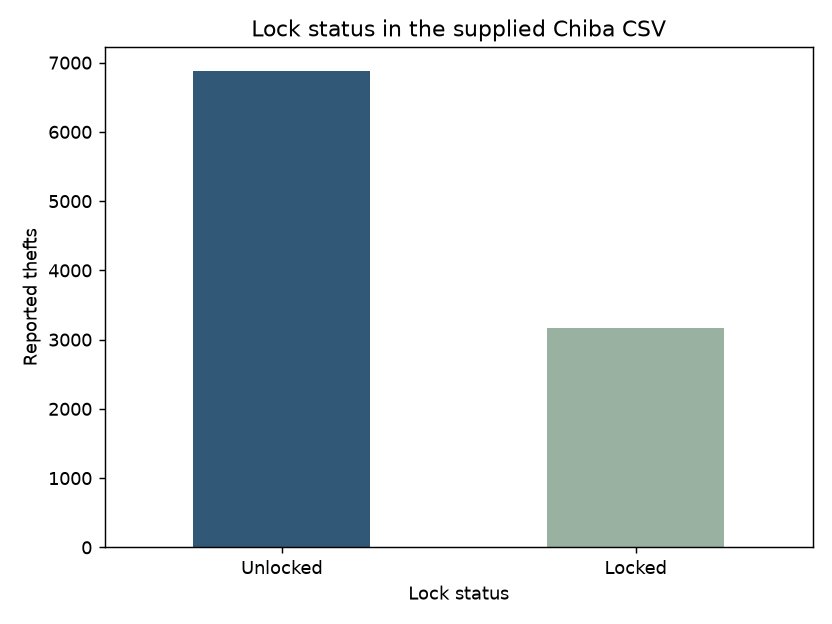

In [13]:
# グラフの文字は英語にして、追加フォントを不要にする
import matplotlib.pyplot as plt
lock_counts = df["施錠関係"].value_counts()
lock_counts.index = lock_counts.index.map({
    "施錠せず": "Unlocked", "施錠した": "Locked"
})

# 棒グラフを描く
lock_counts.plot.bar(color=["#315876", "#98b1a1"], rot=0)
plt.xlabel("Lock status")
plt.ylabel("Reported thefts")
plt.title("Lock status in the supplied Chiba CSV")
plt.tight_layout()
plt.show()

## 問いに戻る

件数の違いから何が言えますか？ 分母（駐輪台数など）がないため、盗まれる確率や施錠の効果は計算できません。

緯度・経度はありません。架空の座標を作って事件地点として表示しないこと。地図は任意。地域の代表点を使う場合は「地域別の集計」と明記してください。

発生日の不明76件、時刻の不明103件を含みます。除外した場合は、何件除外したかを説明してください。

## 任意：タイヤを回す

上の自転車をforで動かしてみよう。4種類のスポークを4周、0.15秒ずつ表示します。clear_outputは前の出力を消し、time.sleepは少し待ちます。Jupyter / VS CodeのNotebookで実行。turns・pause・wheelsを変えてみよう。保存時は最後のコマだけ残します。

In [14]:
# アニメーションの回数と速さを先に設定する
turns = 4
pause = 0.15
wheels = ["-", "\\", "|", "/"]

# Notebookの出力を入れ替える道具。pandasは不要
import time
from IPython.display import clear_output

# 4種類の車輪を順番に表示する。有限回なので自動で止まる
for spoke in wheels * turns:
    clear_output(wait=True)
    print(r"    __o")
    print(r"  _ \<_")
    print(f" ({spoke})/({spoke})")
    time.sleep(pause)

    __o
  _ \<_
 (/)/(/)
